# Testing the detectability of GAIA black holes with photonic lanterns

In [8]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Importing the necessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device
from PLsim.system.lantern import generate_unitary_matrix

import hcipy as hc
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd
from tqdm import tqdm
import astropy.units as u
import astropy.constants as c

# Custom modules
import functions
from PhotonicLanternDevice import PhotonicLanternDevice
from PhotonicLanternFitting import PhotonicLanternFitting

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Loading Smadar's GAIA BH population data

In [9]:
population_data = pd.read_csv('datafiles/GAIAlikeoutput.txt', delimiter='	')
print(population_data.head())

     a [au]         e  a_old [au]     e_old  m_BH [M_sun]    angle1    angle2  \
0  6.186805  0.814824    16.81608  0.682349     12.635595 -0.466941  2.970442   
1  6.659186  0.960413    16.81608  0.682349     12.635595  1.896240  1.597001   
2  6.161268  0.983240    16.81608  0.682349     12.635595 -0.070061 -0.133664   
3  4.403974  0.926148    16.81608  0.682349     12.635595  2.922422  0.542266   
4  4.665931  0.910985    16.81608  0.682349     12.635595  0.305517 -2.464704   

     angle3    angle4    angle5  
0 -0.600848  100.9770  11.87305  
1  2.038747  100.9822  11.86782  
2  1.541220  100.9848  11.86520  
3 -1.483095  100.9892  11.86079  
4 -1.296062  100.9927  11.85727  


### Plotting Smadar's GAIA BH population data

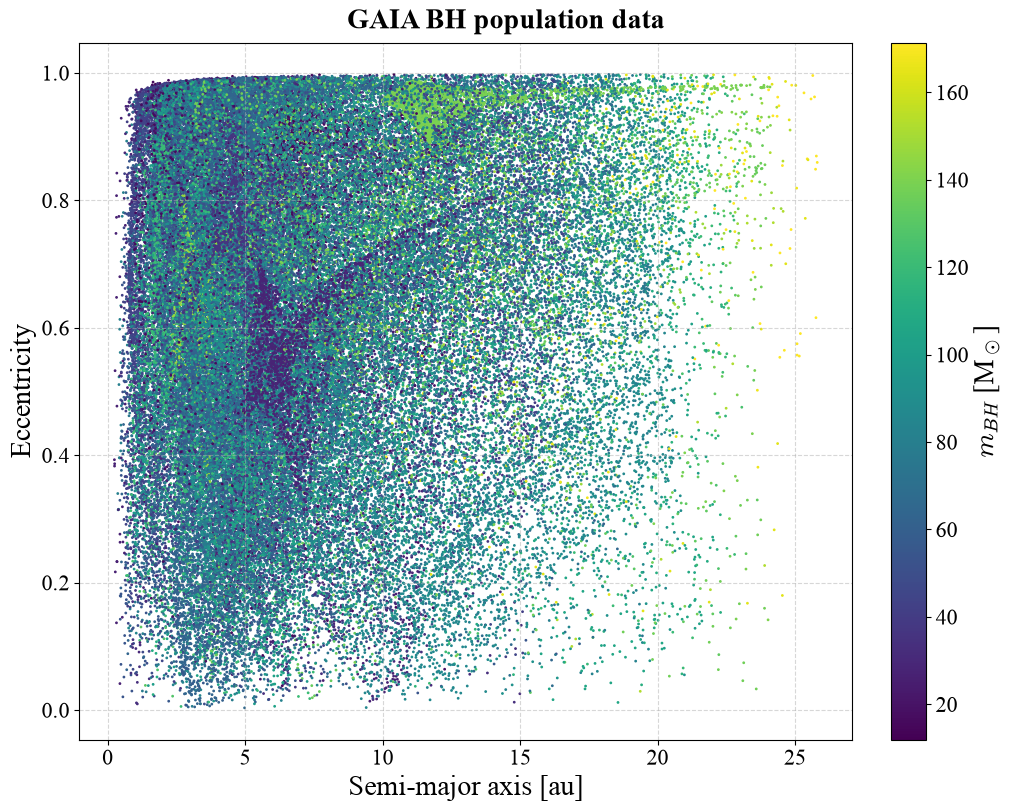

In [10]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('GAIA BH population data')

sc = ax.scatter(population_data['a [au]'], population_data['e'], c=population_data['m_BH [M_sun]'], cmap='viridis', label='GAIA BH population', s=1)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label(r'$m_{BH}$ [M$_\odot$]')

ax.set_xlabel('Semi-major axis [au]')
ax.set_ylabel('Eccentricity')

# ax.legend()

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Creating the photonic lantern device with constants

In [73]:
# Constants
MAS_TO_RAD = 1e-3/206265 # [rad/mas]

# Photonic lantern attributes
N_DIM = 65 # Number of pixels in pupil grid
DIAMETER = 3 # [m], diameter of telescope aperture for pupil
FOCAL_RESOLUTION = 1e-6 # [m], resolution of focal grid (make sure this samples LP modes enough but also not truncate the outer parts)
FOCAL_LENGTH = 40 # [m], focal length of telescope (initial value, OTF.from_fiber_params will find an optimal focal ratio)

# Fiber attributes
N_CORE = 1.444 # Index of refraction of the core
N_CLAD = 1.444 - 5.5e-3 # Index of refraction of the cladding
R_CORE = 10e-6 # [m], core radius

# Wavelengths
N_SPEC = 150 # Number of wavelength channels
WAV_MIDDLE = 1282.8 # [nm], Paschen beta line
WAV_WIDTH = 0.1 # [nm]
WAV_BANDWIDTH = 10*WAV_WIDTH # [nm]
WAV_RANGE = np.linspace(WAV_MIDDLE - WAV_BANDWIDTH/2, WAV_MIDDLE + WAV_BANDWIDTH/2, N_SPEC)

photonic_lantern_device = PhotonicLanternDevice(
    N_DIM=N_DIM,
    DIAMETER=DIAMETER,
    FOCAL_RESOLUTION=FOCAL_RESOLUTION,
    WAV_MIDDLE=WAV_MIDDLE,
    N_CORE=N_CORE,
    N_CLAD=N_CLAD,
    R_CORE=R_CORE,
    FOCAL_LENGTH=FOCAL_LENGTH,
    N_SPEC=N_SPEC
)

fitter = PhotonicLanternFitting(photonic_lantern_device, WAV_RANGE)

Created pupil grid
Created focal grid

Fiber details:
n_core: 1.444
n_clad: 1.4385
r_core: 1e-05 m
ref_wavelength: 1.2828e-06 m

Created aperture
Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02', 'LP31a', 'LP31b', 'LP12a', 'LP12b']
Number of modes:  10
Created optical transfer function

Computed optical transfer function

Generated unitary matrix of shape: (N_SPEC x N_OUTPUTS x N_OUTPUTS) -> (150, 10, 10)

Device initialized with:
  Lantern matrices: (150, 10, 10)
  PIC matrices: None
  Wavelengths: 150
Initialized device with the unitary matrix

Defined scene
Projected scene onto optical transfer function



In [74]:
photonic_lantern_device.angular_extent

159.16892508

## Defining the geometry of the system

In [96]:
# Distance to the system
D_SYSTEM = 100 # [pc]

# Orbital parameters
a = 10 # [au], Semi-major axis
e = 0.2 # Eccentricity
f0 = 0 # [deg] True anomaly at t0

# Mass of the stars
M_1 = 15 # [M_sun]
M_2 = 1 # [M_sun]

# Semimajor axis of the two stars
a1 = a * (M_2 / (M_1 + M_2))
a2 = a * (M_1 / (M_1 + M_2))
print(f'Semimajor axis of the black hole: {a1:.2f} au')
print(f'Semimajor axis of the companion star: {a2:.2f} au')

# Period of the system
P = 2 * np.pi * np.sqrt((a * u.au)**3 / (c.G * (M_1 * u.M_sun + M_2 * u.M_sun))).to(u.yr).value # [yr]
print(f'Period of the system: {P:.2f} years')

# Time of the first observation
t0 = 0

# Time of the observations
N_OBS = 10 # Number of observations
t = np.linspace(t0, t0 + P*u.yr.to(u.s), N_OBS)
delta_t = t[1] - t[0]
print(f'Cadence of the observations: {delta_t:.2f} seconds (every {(delta_t * u.s).to(u.day).value:.2f} days)')

Semimajor axis of the black hole: 0.62 au
Semimajor axis of the companion star: 9.38 au
Period of the system: 7.91 years
Cadence of the observations: 27721049.52 seconds (every 320.85 days)


## Solving Kepler's equation for the true anomaly of each body at each time

In [97]:
def solve_kepler(M, e, tol=1e-8, max_iter=50):
    '''
    Solves Kepler's equation M = E - e*sin(E) for eccentric anomaly E.
    
    Parameters
    ----------
    M : float or np.ndarray
        Mean anomaly in radians.
    e : float or np.ndarray
        Eccentricity (must be 0 <= e < 1).
    tol : float
        Tolerance for convergence.
    max_iter : int
        Maximum number of Newton-Raphson iterations.
    
    Returns
    -------
    E : float or np.ndarray
        Eccentric anomaly in radians.
    '''
    # Wrap M to the [0, 2*pi] domain for numerical stability
    M = np.mod(M, 2 * np.pi)
    
    # Initial guess
    E = M + e * np.sin(M)
    
    for _ in range(max_iter):
        # Calculate the function and its derivative
        f = E - e * np.sin(E) - M
        f_prime = 1.0 - e * np.cos(E)
        
        # Calculate the Newton-Raphson step
        delta_E = f / f_prime
        E = E - delta_E
        
        # Check if the largest error in the array is below tolerance
        if np.max(np.abs(delta_E)) < tol:
            break
            
    return E

def compute_perifocal_state(a, e, M_total, E, G=c.G):
    '''
    Computes exact position and velocity vectors in the orbital plane.
    
    Parameters
    ----------
    a : float
        Total semi-major axis of the relative orbit
    e : float
        Eccentricity
    M_total : float
        Total system mass (m1 + m2) in solar masses
    E : np.ndarray
        Eccentric anomaly array from the Kepler solver
    G : float
        Gravitational constant in your chosen units
    
    Returns
    -------
    r_vec : np.ndarray
        Shape (N, 3) relative position vectors
    v_vec : np.ndarray
        Shape (N, 3) relative velocity vectors
    '''
    # Shared mean motion
    n = np.sqrt(c.G * (M_1*u.M_sun + M_2*u.M_sun).to(u.kg) / (a * u.au).to(u.km)**3).to(1/u.s).value
    
    # 1. Relative Position in perifocal coordinates (z = 0)
    x = a * (np.cos(E) - e)
    y = a * np.sqrt(1 - e**2) * np.sin(E)
    z = np.zeros_like(E)
    r_vec = np.column_stack((x, y, z))
    
    # 2. Relative Velocity in perifocal coordinates
    E_dot_factor = n / (1 - e * np.cos(E))
    vx = -a * np.sin(E) * E_dot_factor
    vy = a * np.sqrt(1 - e**2) * np.cos(E) * E_dot_factor
    vz = np.zeros_like(E)
    v_vec = np.column_stack((vx, vy, vz))
    
    return r_vec, v_vec

In [98]:
# Mean motion
n = 2 * np.pi / (P*u.yr.to(u.s)) # [rad/s]
print(f'Mean motion: {n:.2e} rad/s')

# Creating array of mean anomalies
M = n * t

# Solving Kepler's equation for the eccentric anomaly
E = np.zeros(N_OBS)
for i in tqdm(range(N_OBS), desc='Solving Kepler\'s equation'):
    E[i] = solve_kepler(M[i], e)

r_rel, v_rel = compute_perifocal_state(a, e, M_1 + M_2, E)

# Black hole
r1 = (M_2 / (M_1 + M_2)) * r_rel
v1 = (M_2 / (M_1 + M_2)) * v_rel

# Companion star
r2 = -(M_1 / (M_1 + M_2)) * r_rel
v2 = -(M_1 / (M_1 + M_2)) * v_rel

Mean motion: 2.52e-08 rad/s


Solving Kepler's equation: 100%|██████████| 10/10 [00:00<00:00, 10080.04it/s]


### Plotting the in-plane position of the two stars at each time

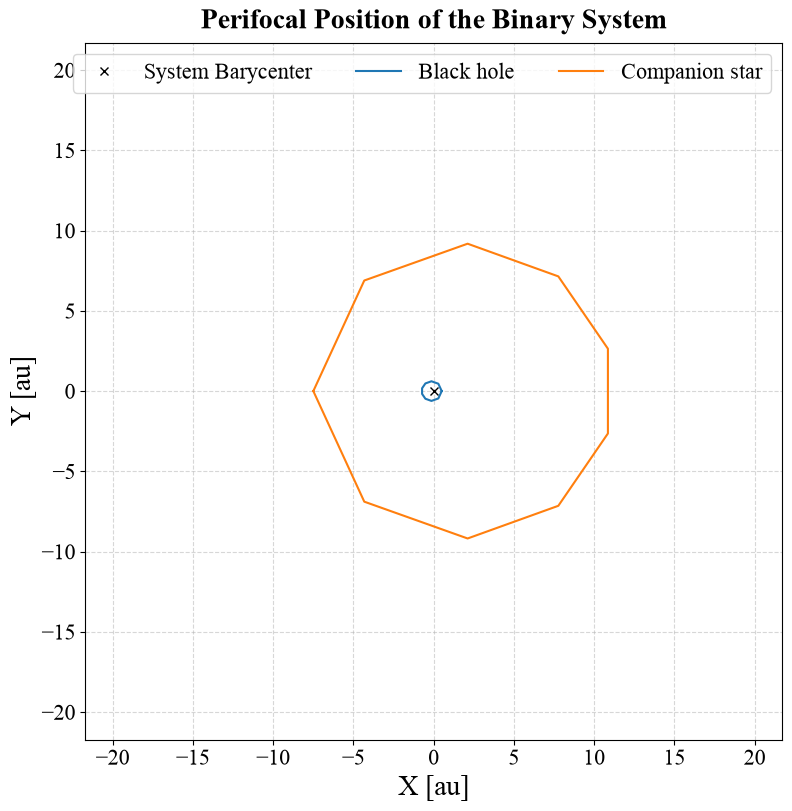

In [99]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Perifocal Position of the Binary System')

ax.plot(0, 0, 'x', color='k', label='System Barycenter')

ax.plot(r1[:, 0], r1[:, 1], label='Black hole')
ax.plot(r2[:, 0], r2[:, 1], label='Companion star')

max_distance = np.max([np.max(r1), np.max(r2)])

ax.set_xlim(-2*max_distance, 2*max_distance)
ax.set_ylim(-2*max_distance, 2*max_distance)

ax.set_xlabel('X [au]')
ax.set_ylabel('Y [au]')
ax.set_aspect('equal')

ax.legend(ncol=3)

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Consistency check: angular momentum is conserved

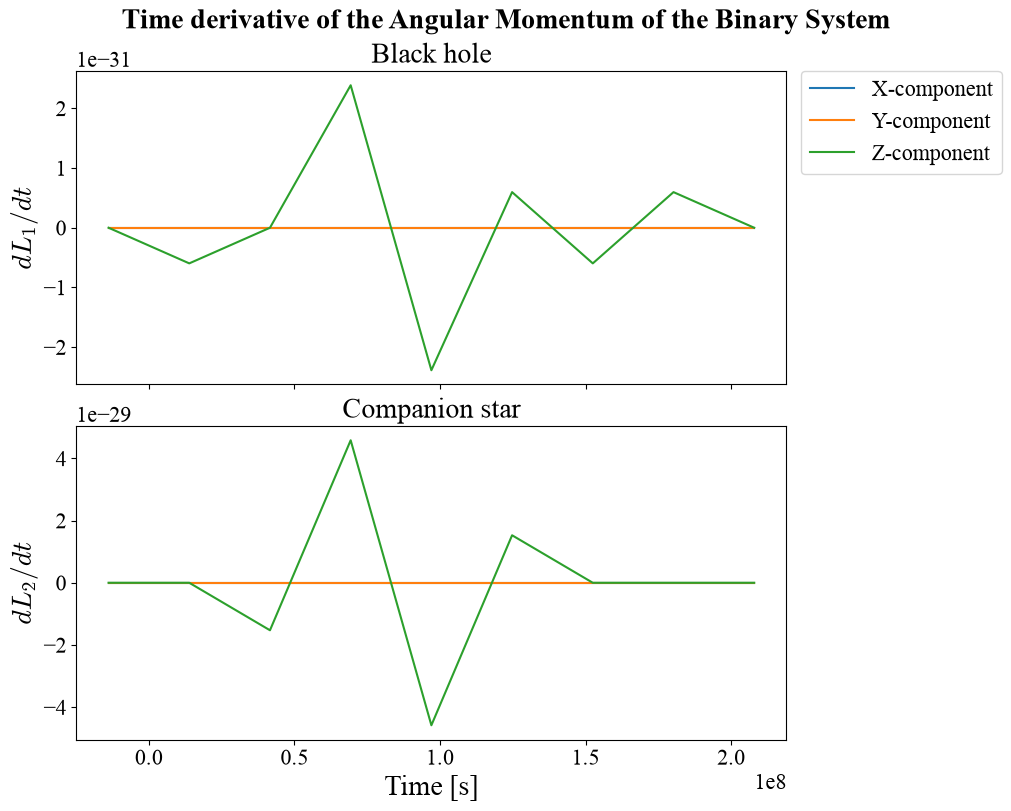

In [100]:
L1 = np.cross(r1, v1)
L2 = np.cross(r2, v2)

dL1dt = np.diff(L1, axis=0) / np.diff(t).reshape(-1, 1)
dL2dt = np.diff(L2, axis=0) / np.diff(t).reshape(-1, 1)

fig = plt.figure()
fig.set_constrained_layout(True)
axes = fig.subplots(2, 1, sharex=True)
axes = axes.flatten()

fig.suptitle('Time derivative of the Angular Momentum of the Binary System')

axes[0].set_title('Black hole')
axes[0].plot(t[:-1] - delta_t/2, dL1dt[:, 0], label='X-component')
axes[0].plot(t[:-1] - delta_t/2, dL1dt[:, 1], label='Y-component')
axes[0].plot(t[:-1] - delta_t/2, dL1dt[:, 2], label='Z-component')

axes[1].set_title('Companion star')
axes[1].plot(t[:-1] - delta_t/2, dL2dt[:, 0], label='X-component')
axes[1].plot(t[:-1] - delta_t/2, dL2dt[:, 1], label='Y-component')
axes[1].plot(t[:-1] - delta_t/2, dL2dt[:, 2], label='Z-component')

axes[1].set_xlabel('Time [s]')
axes[0].set_ylabel('$dL_1/dt$')
axes[1].set_ylabel('$dL_2/dt$')


axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

### Converting the system into 3D coordinates

In [101]:
def rotate_to_3d(vecs, i, omega, Omega):
    '''
    Rotates (N, 3) perifocal vectors into the 3D reference frame.
    
    Parameters
    ----------
    vecs : np.ndarray
        Shape (N, 3) array of position or velocity vectors
    i : float
        Inclination in degrees
    omega : float
        Argument of periapsis in degrees
    Omega : float
        Right ascension of the ascending node in degrees
    
    Returns
    -------
    vecs_3d : np.ndarray
        Shape (N, 3) rotated 3D vectors
    '''
    # Convert angles to radians
    omega = np.deg2rad(omega)
    Omega = np.deg2rad(Omega)
    i = np.deg2rad(i)

    # Pre-calculate trigonometric terms
    cw, sw = np.cos(omega), np.sin(omega)
    cO, sO = np.cos(Omega), np.sin(Omega)
    ci, si = np.cos(i), np.sin(i)
    
    # Construct the Direction Cosine Matrix (DCM)
    R11 = cO * cw - sO * sw * ci
    R12 = -cO * sw - sO * cw * ci
    R13 = sO * si
    
    R21 = sO * cw + cO * sw * ci
    R22 = -sO * sw + cO * cw * ci
    R23 = -cO * si
    
    R31 = sw * si
    R32 = cw * si
    R33 = ci
    
    DCM = np.array([
        [R11, R12, R13],
        [R21, R22, R23],
        [R31, R32, R33]
    ])
    
    # Apply rotation (vecs @ DCM.T for row-wise multiplication)
    vecs_3d = vecs @ DCM.T
    
    return vecs_3d

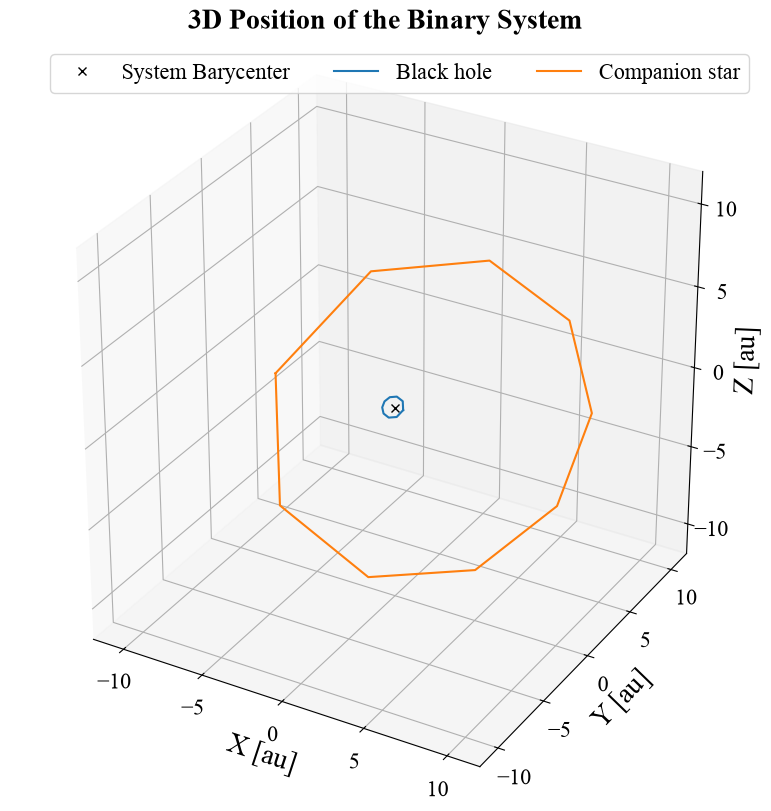

In [102]:
inclination = 45 # [deg] Inclination with respect to the plane of the sky
argument_of_periapse = 0 # [deg] Argument of periapse
right_ascension_of_ascending_node = 0 # [deg] Longitude of ascending node

# 1. Rotate the RELATIVE vectors first (cheaper than rotating both stars)
r_rel_3d = rotate_to_3d(r_rel, inclination, argument_of_periapse, right_ascension_of_ascending_node)
v_rel_3d = rotate_to_3d(v_rel, inclination, argument_of_periapse, right_ascension_of_ascending_node)

# 2. Scale into 3D barycentric vectors for each star
# (Using the same mass fractions derived previously)
r1_3d = (M_2 / (M_1 + M_2)) * r_rel_3d
v1_3d = (M_2 / (M_1 + M_2)) * v_rel_3d

r2_3d = -(M_1 / (M_1 + M_2)) * r_rel_3d
v2_3d = -(M_1 / (M_1 + M_2)) * v_rel_3d

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot(projection='3d')

fig.suptitle('3D Position of the Binary System')

ax.plot(0, 0, 0, 'x', color='k', label='System Barycenter')

ax.plot(r1_3d[:, 0], r1_3d[:, 1], r1_3d[:, 2], label='Black hole')
ax.plot(r2_3d[:, 0], r2_3d[:, 1], r2_3d[:, 2], label='Companion star')

max_distance = np.max([np.max(r1_3d), np.max(r2_3d)])

ax.set_xlim(-1.1*max_distance, 1.1*max_distance)
ax.set_ylim(-1.1*max_distance, 1.1*max_distance)
ax.set_zlim(-1.1*max_distance, 1.1*max_distance)

ax.set_xlabel('X [au]')
ax.set_ylabel('Y [au]')
ax.set_zlabel('Z [au]')

ax.set_aspect('equal')

ax.legend(ncol=3)

plt.show()

### Projecting the orbits into the plane of the sky (Z axis is the line of sight)

In [103]:
def compute_angular_separation(r_rel_3d, distance_pc):
    '''
    Converts 3D relative Cartesian coordinates to projected angular separation.
    
    Parameters:
    r_rel_3d : np.ndarray
        Shape (N, 3) relative position vectors in AU
    distance_pc : float
        Distance to the binary system in parsecs
    
    Returns:
    x_arcsec : np.ndarray
        Shape (N,) projected X-coordinate in mas
    y_arcsec : np.ndarray
        Shape (N,) projected Y-coordinate in mas
    '''
    # Project onto the sky plane by slicing out X and Y
    x_rel = r_rel_3d[:, 0]
    y_rel = r_rel_3d[:, 1]

    # Convert to mas
    x_mas = x_rel / distance_pc * 1000 # [mas]
    y_mas = y_rel / distance_pc * 1000 # [mas]

    return x_mas, y_mas

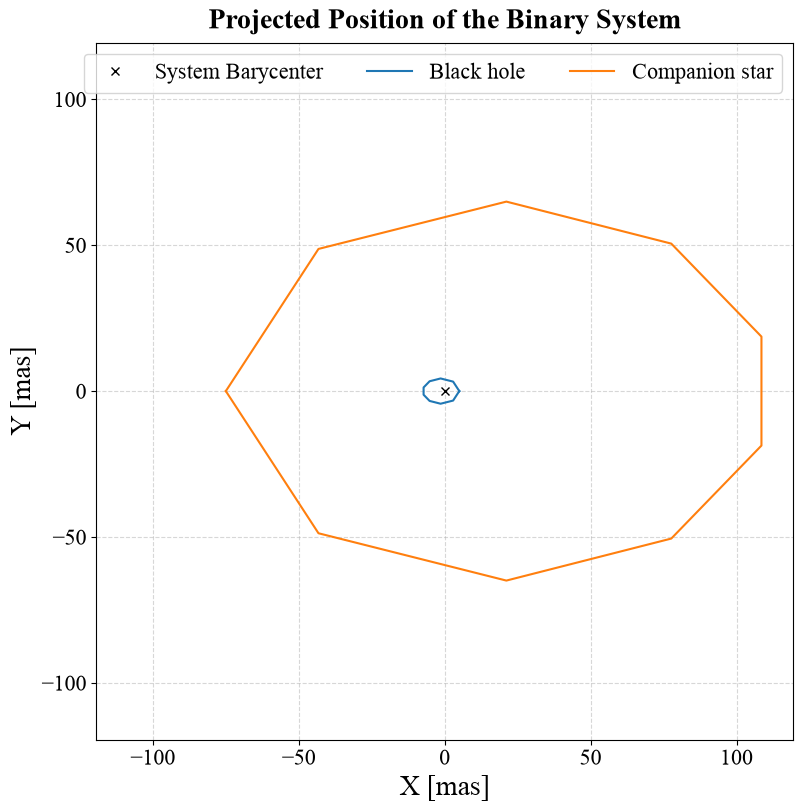

In [104]:
x1_proj, y1_proj = compute_angular_separation(r1_3d, D_SYSTEM)
x2_proj, y2_proj = compute_angular_separation(r2_3d, D_SYSTEM)

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Projected Position of the Binary System')

ax.plot(0, 0, 'x', color='k', label='System Barycenter')

ax.plot(x1_proj, y1_proj, label='Black hole')
ax.plot(x2_proj, y2_proj, label='Companion star')

max_distance = np.max([np.max(x1_proj), np.max(x2_proj), np.max(y1_proj), np.max(y2_proj)])

ax.set_xlim(-1.1*max_distance, 1.1*max_distance)
ax.set_ylim(-1.1*max_distance, 1.1*max_distance)

ax.set_xlabel('X [mas]')
ax.set_ylabel('Y [mas]')

ax.set_aspect('equal')

ax.legend(ncol=3)

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Velocity along the line of sight

In [105]:
# Velocity along the line of sight
v_z1 = np.dot(v1_3d, np.array([0, 0, 1]))*(u.au/u.s).to(u.km/u.s) # [km/s]
v_z2 = np.dot(v2_3d, np.array([0, 0, 1]))*(u.au/u.s).to(u.km/u.s) # [km/s]

# Change in wavelength due to Doppler shift
delta_lambda1 = v_z1 / c.c.to(u.km/u.s).value * WAV_MIDDLE # [nm]
delta_lambda2 = v_z2 / c.c.to(u.km/u.s).value * WAV_MIDDLE # [nm]

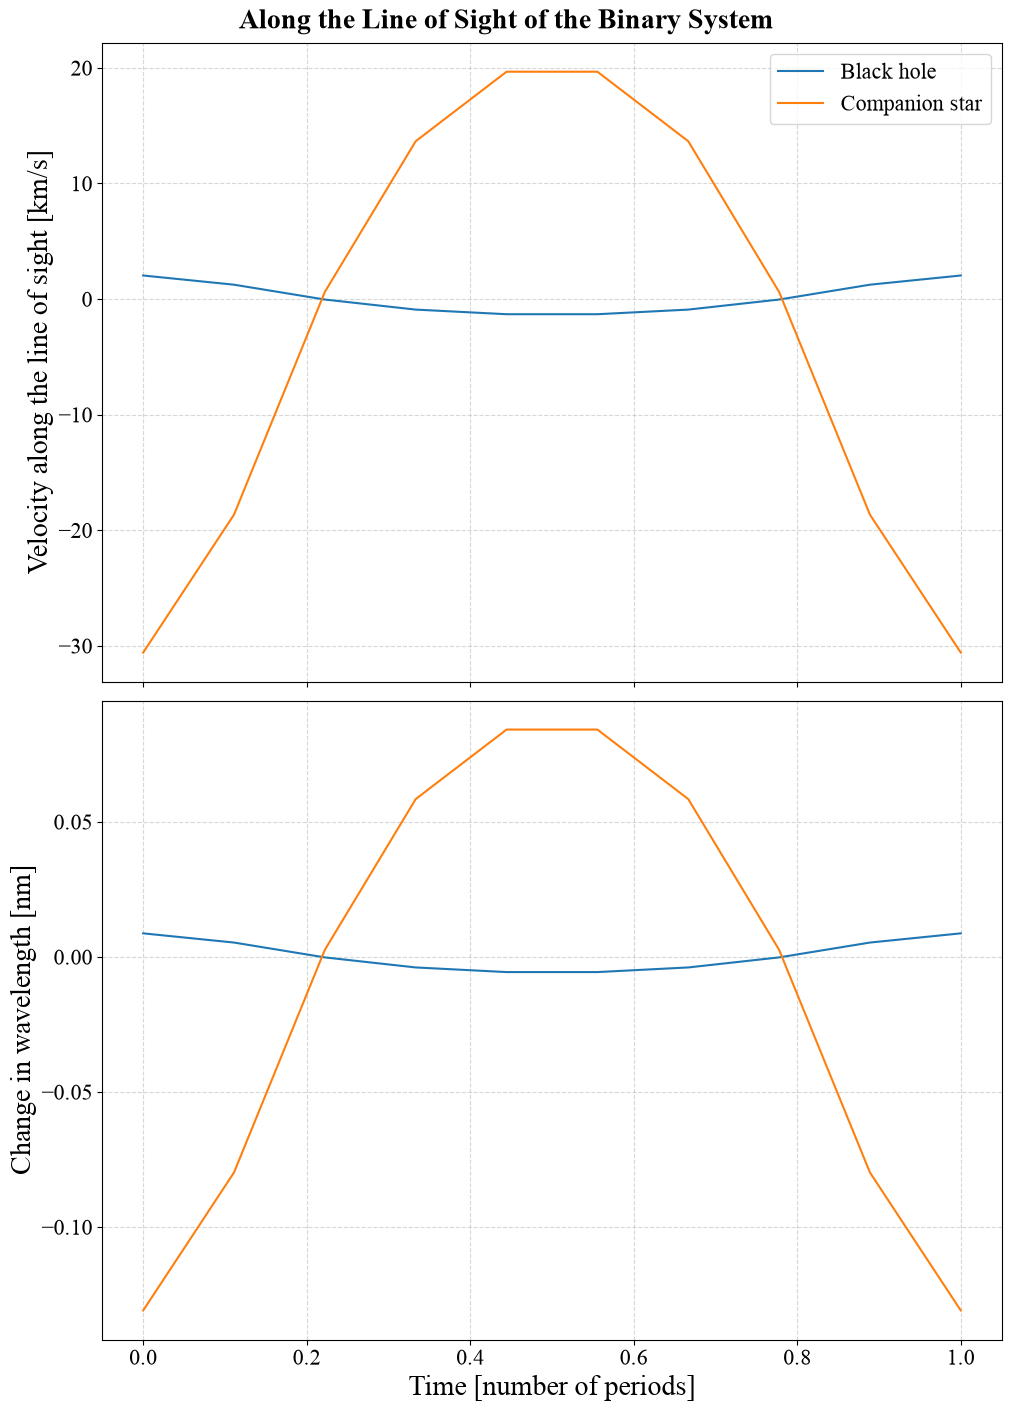

In [106]:
fig = plt.figure(figsize=(10, 14))
fig.set_constrained_layout(True)
axes = fig.subplots(nrows=2, sharex=True)

fig.suptitle('Along the Line of Sight of the Binary System')

axes[0].plot(t*u.s.to(u.yr)/P, v_z1, label='Black hole')
axes[0].plot(t*u.s.to(u.yr)/P, v_z2, label='Companion star')

axes[0].set_ylabel('Velocity along the line of sight [km/s]')

axes[0].legend()

axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(t*u.s.to(u.yr)/P, delta_lambda1, label='Black hole')
axes[1].plot(t*u.s.to(u.yr)/P, delta_lambda2, label='Companion star')

axes[1].set_xlabel('Time [number of periods]')
axes[1].set_ylabel('Change in wavelength [nm]')

axes[1].grid(True, linestyle='--', alpha=0.5)

plt.show()

## Defining spectral features of the stars

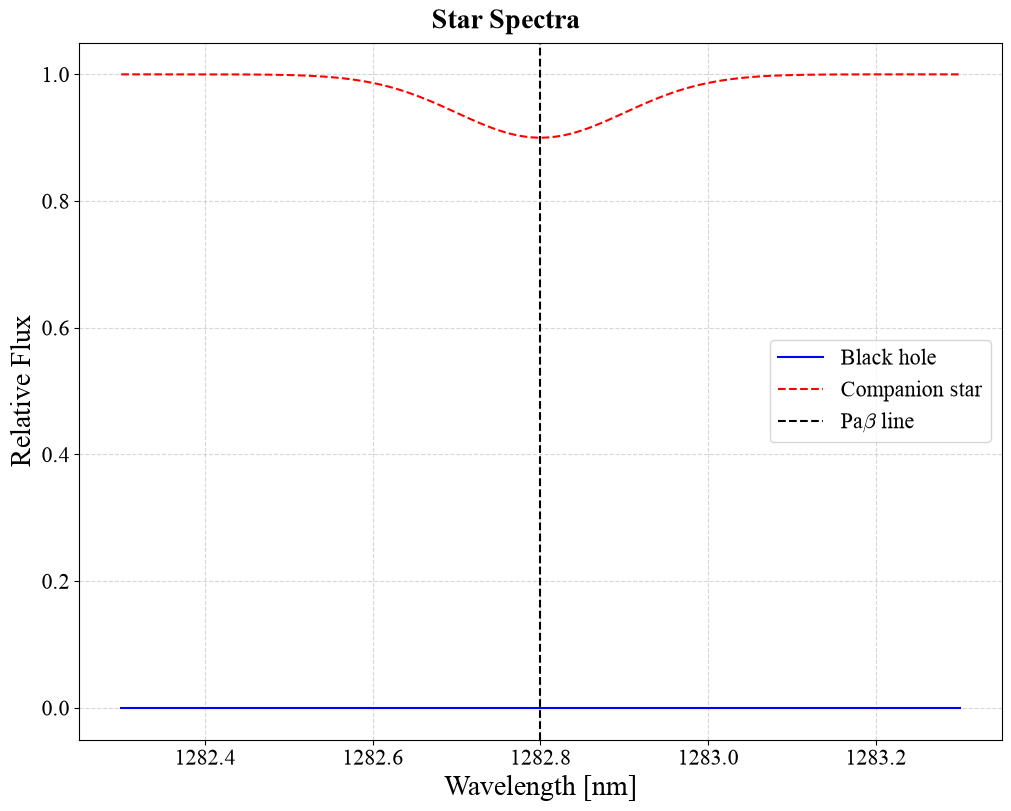

In [107]:
# Flux of the continuum of the stars
F_1 = 0
F_2 = 1

# Depth of the line
A_LINE_1 = 0.9
A_LINE_2 = 0.9

# Middle wavelength of each absorption line
WAV_MIDDLE_1 = WAV_MIDDLE
WAV_MIDDLE_2 = WAV_MIDDLE

# Width of each absorption line
WAV_WIDTH_1 = WAV_WIDTH
WAV_WIDTH_2 = WAV_WIDTH

# Spectrum of star 1
star1_spectrum = functions.create_spectrum(F_1, A_LINE_1, WAV_MIDDLE_1, WAV_WIDTH_1, WAV_RANGE)

# Spectrum of star 2
star2_spectrum = functions.create_spectrum(F_2, A_LINE_2, WAV_MIDDLE_2, WAV_WIDTH_2, WAV_RANGE)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(WAV_RANGE, star1_spectrum, label='Black hole', color='b', linestyle='-')
ax.plot(WAV_RANGE, star2_spectrum, label='Companion star', color='r', linestyle='--')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

Shifting the spectra due to the Doppler shift: 100%|██████████| 10/10 [00:00<00:00, 17070.83it/s]


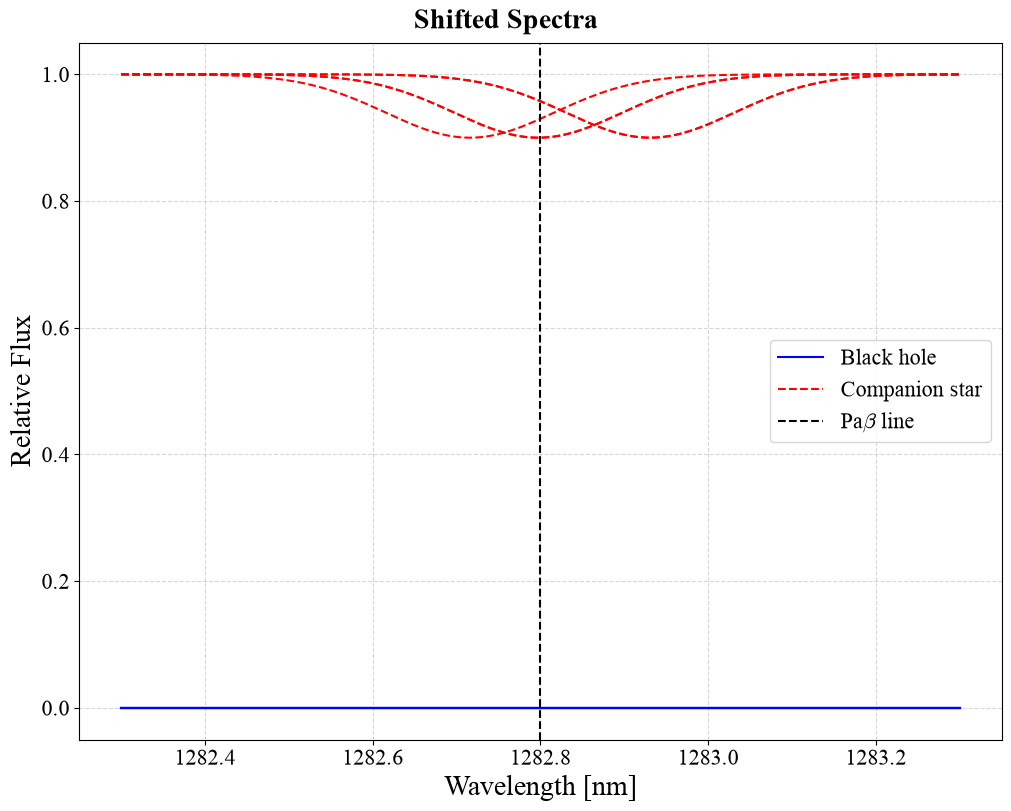

In [108]:
star1_spectra_doppled = np.zeros((N_OBS, N_SPEC))
star2_spectra_doppled = np.zeros((N_OBS, N_SPEC))

for i in tqdm(range(N_OBS), desc='Shifting the spectra due to the Doppler shift'):
    star1_spectra_doppled[i, :] = functions.create_spectrum(F_1, A_LINE_1, WAV_MIDDLE_1, WAV_WIDTH_1, WAV_RANGE + delta_lambda1[i])
    star2_spectra_doppled[i, :] = functions.create_spectrum(F_2, A_LINE_2, WAV_MIDDLE_2, WAV_WIDTH_2, WAV_RANGE + delta_lambda2[i])

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Shifted Spectra')

for i in range(N_OBS):
    if i == 0 or i == N_OBS//4 or i == N_OBS//2 or i == 3*N_OBS//4 or i == N_OBS - 1:
        ax.plot(WAV_RANGE, star1_spectra_doppled[i], label=f'Black hole' if i == 0 else None, color='b', linestyle='-')
        ax.plot(WAV_RANGE, star2_spectra_doppled[i], label=f'Companion star' if i == 0 else None, color='r', linestyle='--')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

## Passing time-varying spectra and positions through the photonic lantern device

In [109]:
intensities = np.zeros((N_OBS, photonic_lantern_device.N_PORTS))
signals = np.zeros((N_OBS, photonic_lantern_device.N_PORTS))
single_residuals = np.zeros(N_OBS)

for i in tqdm(range(N_OBS), desc='Passing the spectra and positions through the photonic lantern device'):
    positions = np.array([[x1_proj[i], y1_proj[i]], [x2_proj[i], y2_proj[i]]])
    spectra = np.array([star1_spectra_doppled[i], star2_spectra_doppled[i]])

    outputs = photonic_lantern_device.calculate_photonic_lantern_outputs(positions, spectra, noise=1e-3, seed=i)

    intensities[i, :] = functions.calculate_normalized_intensities(outputs, 0, WAV_RANGE)
    signals[i, :] = functions.calculate_signal(outputs, WAV_RANGE)
    
    # # Computing the total intensities across all outputs as a function of wavelength
    # total_intensity = np.sum(outputs, axis=1)

    # # Computing fractional intensities for the outputs
    # fractional_intensity = outputs / total_intensity.reshape(-1, 1)

    # result = fitter.single_fitting(fractional_intensity)

    # single_residuals[i] = result.fun


Passing the spectra and positions through the photonic lantern device:   0%|          | 0/10 [00:00<?, ?it/s]

Passing the spectra and positions through the photonic lantern device: 100%|██████████| 10/10 [00:00<00:00, 82.98it/s]


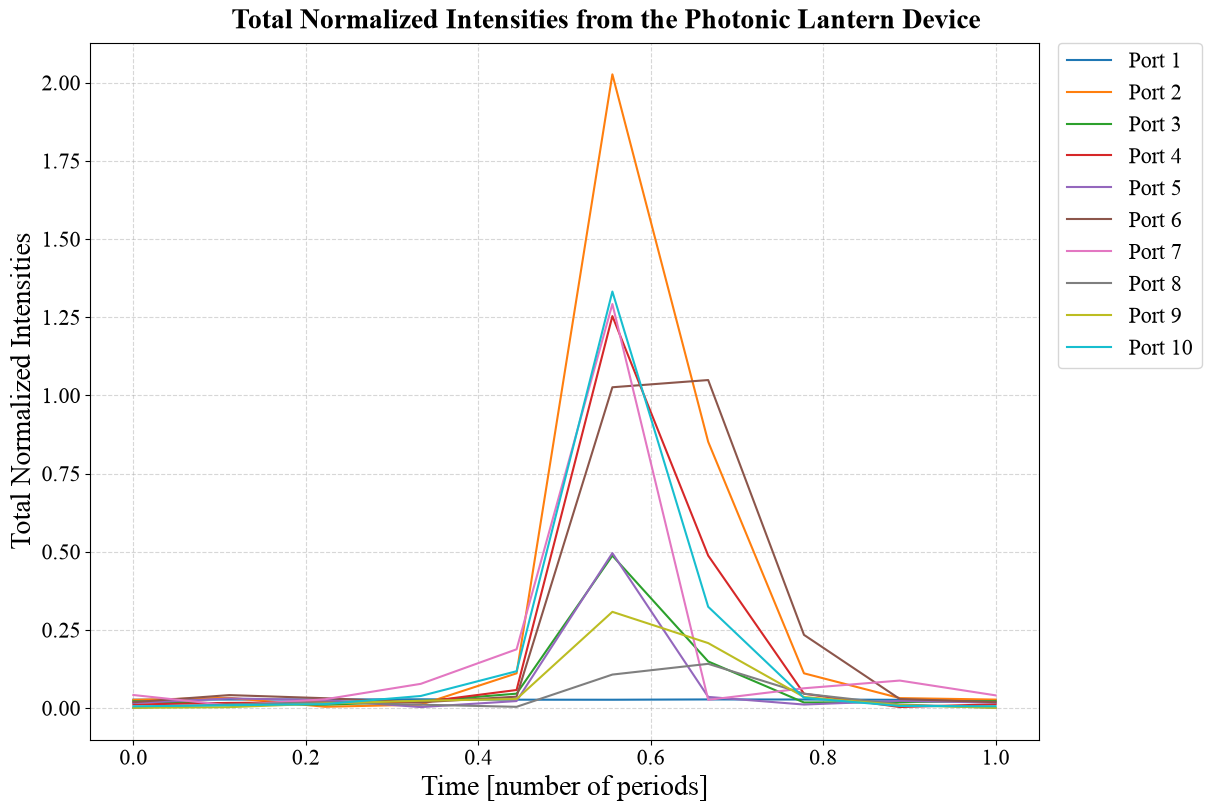

In [110]:
fig = plt.figure(figsize=(12, 8))
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle(f'Total Normalized Intensities from the Photonic Lantern Device')

for i in range(photonic_lantern_device.N_PORTS):
    ax.plot(t*u.s.to(u.yr)/P, intensities[:, i], label=f'Port {i+1}')

ax.set_xlabel('Time [number of periods]')
ax.set_ylabel('Total Normalized Intensities')

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

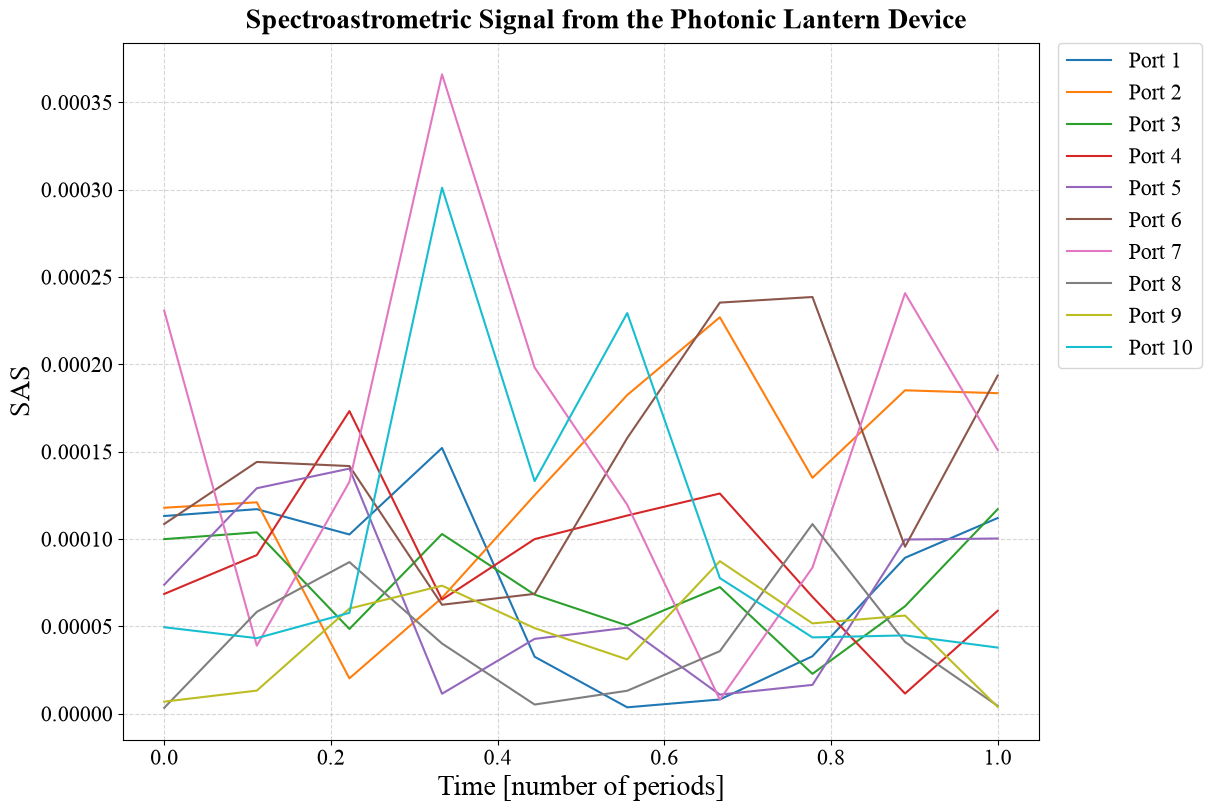

In [111]:
fig = plt.figure(figsize=(12, 8))
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle(f'Spectroastrometric Signal from the Photonic Lantern Device')

for i in range(photonic_lantern_device.N_PORTS):
    ax.plot(t*u.s.to(u.yr)/P, signals[:, i], label=f'Port {i+1}')

ax.set_xlabel('Time [number of periods]')
ax.set_ylabel('SAS')

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Since the SAS is on order of the noise, let's fit a single star to the data and store the locations of the star

In [115]:
single_residuals = np.zeros(N_OBS)
single_xs = np.zeros(N_OBS)
single_ys = np.zeros(N_OBS)

for i in tqdm(range(N_OBS), desc='Passing the spectra and positions through the photonic lantern device'):
    positions = np.array([[x1_proj[i], y1_proj[i]], [x2_proj[i], y2_proj[i]]])
    spectra = np.array([star1_spectra_doppled[i], star2_spectra_doppled[i]])

    outputs = photonic_lantern_device.calculate_photonic_lantern_outputs(positions, spectra, noise=1, seed=i)
    
    # Computing the total intensities across all outputs as a function of wavelength
    total_intensity = np.sum(outputs, axis=1)

    # Computing fractional intensities for the outputs
    fractional_intensity = outputs / total_intensity.reshape(-1, 1)

    result = fitter.single_fitting(fractional_intensity)

    single_residuals[i] = result.fun
    single_xs[i] = result.x[0]
    single_ys[i] = result.x[1]

Passing the spectra and positions through the photonic lantern device: 100%|██████████| 10/10 [00:03<00:00,  2.65it/s]


### Plotting the results of the single star fitting

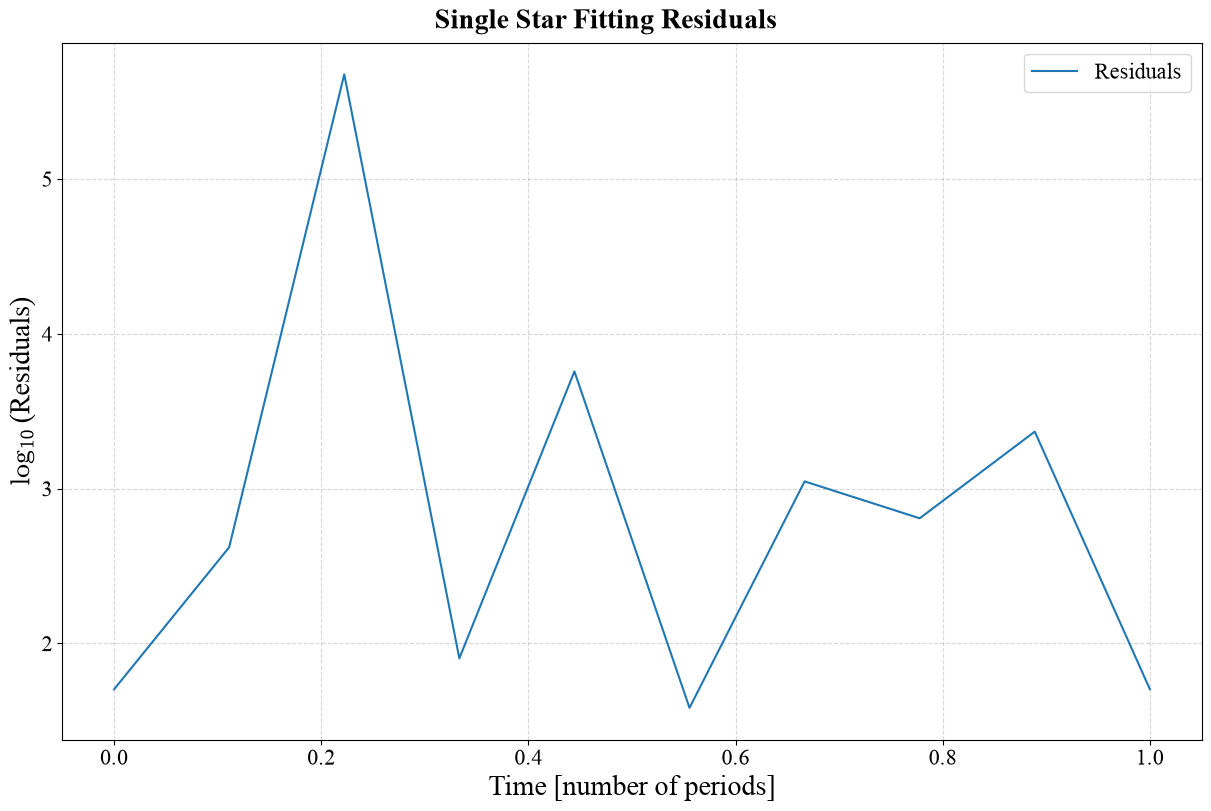

In [116]:
fig = plt.figure(figsize=(12, 8))
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle(f'Single Star Fitting Residuals')

ax.plot(t*u.s.to(u.yr)/P, np.log10(single_residuals), label='Residuals')

ax.set_xlabel('Time [number of periods]')
ax.set_ylabel('$\log_{10}$(Residuals)')

ax.legend()

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

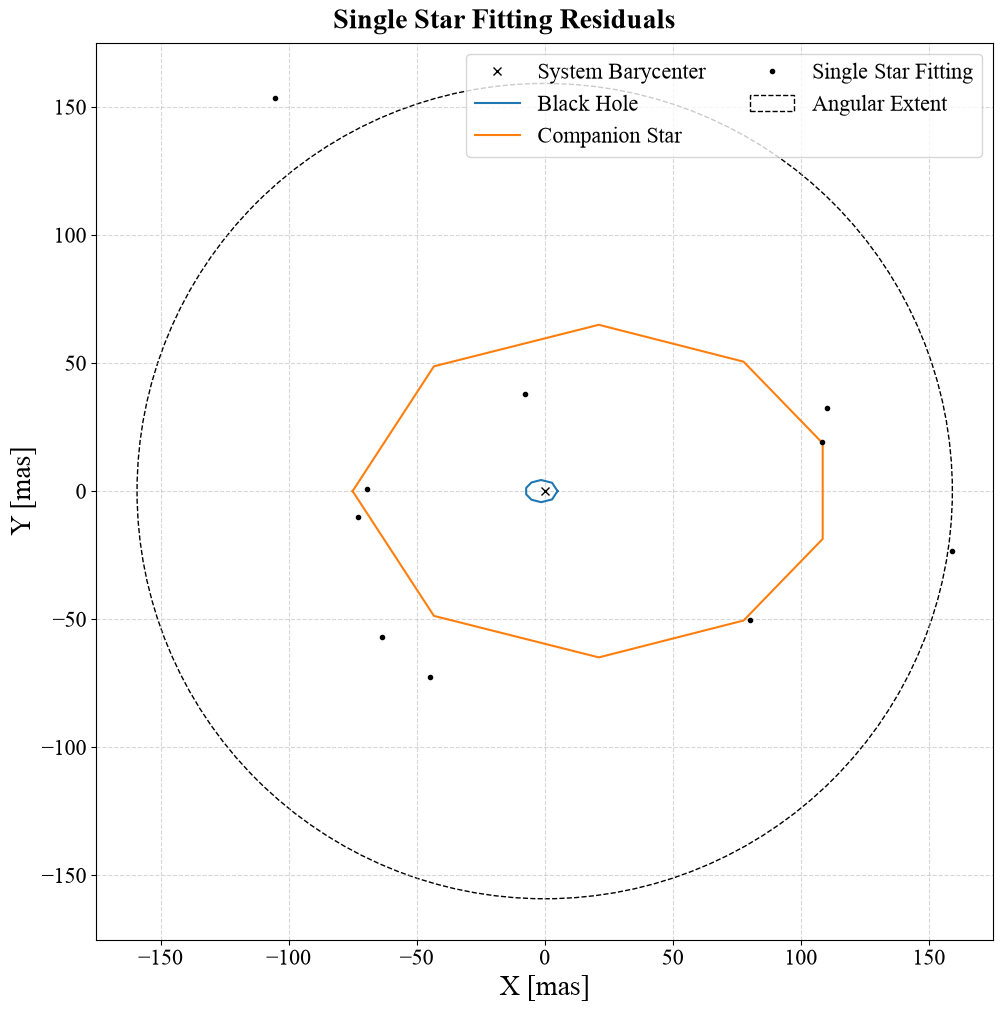

In [117]:
fig = plt.figure(figsize=(10, 10))
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle(f'Single Star Fitting Residuals')

ax.plot(0, 0, 'x', color='k', label='System Barycenter')

ax.plot(x1_proj, y1_proj, label='Black Hole')
ax.plot(x2_proj, y2_proj, label='Companion Star')

ax.plot(single_xs, single_ys, '.', color='k', label='Single Star Fitting')

max_distance = np.max([np.max(x1_proj), np.max(x2_proj), np.max(y1_proj), np.max(y2_proj), np.max(single_xs), np.max(single_ys)])

angular_extent_patch = patches.Circle((0, 0), photonic_lantern_device.angular_extent, color='k', fill=False, linestyle='--', label='Angular Extent')
ax.add_patch(angular_extent_patch)

ax.set_xlabel('X [mas]')
ax.set_ylabel('Y [mas]')

ax.set_xlim(-1.1*max_distance, 1.1*max_distance)
ax.set_ylim(-1.1*max_distance, 1.1*max_distance)

ax.set_aspect('equal')

ax.legend(ncol=2)

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()